# Especialización en MLOps Engineer
## Módulo 1 · Sesión 2 — Arquitectura profesional de un proyecto de Machine Learning

**Objetivo general:** transformar un notebook experimental en una estructura modular, configurable, testeable y reproducible.

> El cuaderno construye un proyecto completo dentro de `./mlops_professional_project` y puede ejecutarse de arriba hacia abajo en Google Colab.

### Método de trabajo
En cada etapa preguntaremos:
1. ¿qué responsabilidad queremos aislar?;
2. ¿en qué archivo debe vivir?;
3. ¿qué entradas recibe?;
4. ¿qué salida produce?;
5. ¿cómo verificamos automáticamente que funciona?;
6. ¿qué error de arquitectura evitamos?

### Al finalizar podrás
- organizar un repositorio profesional de ML;
- separar configuración, datos, entrenamiento e inferencia;
- registrar eventos con `logging`;
- validar artefactos e inputs;
- crear pruebas automáticas con `pytest`;
- ejecutar el proyecto como un pipeline;
- empaquetar la arquitectura para GitHub, CI/CD, Docker o FastAPI.

### Idea guía
Buscamos **alta cohesión** y **bajo acoplamiento**: cada módulo resuelve un problema concreto y conoce lo mínimo necesario sobre los demás.

## 1. Glosario de siglas y conceptos

| Término | Significado | Uso |
|---|---|---|
| **YAML** | *YAML Ain't Markup Language* | Configuración legible por humanos. |
| **JSON** | *JavaScript Object Notation* | Metadatos y resultados estructurados. |
| **CLI** | *Command-Line Interface* | Ejecución mediante comandos. |
| **API** | *Application Programming Interface* | Contrato para comunicar aplicaciones. |
| **CI** | *Continuous Integration* | Ejecuta validaciones ante cambios. |
| **CD** | *Continuous Delivery/Deployment* | Automatiza entrega o despliegue. |
| **ETL** | *Extract, Transform, Load* | Extraer, transformar y cargar datos. |
| **ELT** | *Extract, Load, Transform* | Extraer, cargar y transformar después. |
| **Logging** | Registro de eventos | Permite investigar errores y operación. |
| **Schema** | Esquema | Contrato de columnas, tipos y estructura. |
| **Unit test** | Prueba unitaria | Verifica una unidad pequeña. |
| **Integration test** | Prueba de integración | Verifica colaboración entre componentes. |

Dos conceptos de diseño:
- **cohesión:** un módulo concentra responsabilidades relacionadas;
- **acoplamiento:** cuánto depende un módulo de otros. Buscamos acoplamiento bajo.

## Ruta de aprendizaje de la sesión

**Parte 1 — Diseñar:** estructura de carpetas y responsabilidades.  
**Parte 2 — Configurar:** dependencias, YAML, rutas y logging.  
**Parte 3 — Modularizar:** datos, entrenamiento e inferencia separados.  
**Parte 4 — Verificar:** tests, smoke tests, contratos y manejo de errores.  
**Parte 5 — Automatizar:** entry point, manifiesto y preparación para CI/CD.

El criterio de calidad será: **otra persona debería poder entender, ejecutar y verificar el proyecto sin depender del estado interno del notebook**.

## 2. Estructura profesional

```text
mlops_professional_project/
├── config/
│   └── config.yaml
├── data/
│   ├── raw/
│   └── processed/
├── logs/
├── models/
├── reports/
├── src/
│   └── mlops_demo/
│       ├── __init__.py
│       ├── config.py
│       ├── data.py
│       ├── logging_utils.py
│       ├── train.py
│       └── inference.py
├── tests/
│   ├── test_data.py
│   └── test_inference.py
├── requirements.txt
└── README.md
```

Cada componente tiene una responsabilidad concreta.

### Construir primero la estructura
Antes de escribir lógica creamos una jerarquía estable. Esto permite que rutas, pruebas y automatizaciones sepan dónde encontrar cada tipo de artefacto.

La carpeta `raw` representa datos de entrada preservados; `processed` representa salidas de preparación. Separarlas mejora trazabilidad.

In [ ]:
from pathlib import Path
import os
import shutil
import sys
import json
import textwrap

# La raíz se deriva del directorio actual para que el proyecto sea portable.
# En Google Colab, Path.cwd() normalmente es /content.
PROJECT_ROOT = Path.cwd() / "mlops_professional_project"

# Borramos una ejecución anterior para evitar que archivos obsoletos
# hagan parecer que el pipeline actual produjo artefactos que en realidad son viejos.
if PROJECT_ROOT.exists():
    shutil.rmtree(PROJECT_ROOT)

folders = [
    "config",            # parámetros editables sin modificar código
    "data/raw",          # copia de entrada preservada
    "data/processed",    # train, validation y test generados
    "logs",              # trazabilidad operacional
    "models",            # modelos y schemas serializados
    "reports",           # métricas y reportes estructurados
    "src/mlops_demo",    # código fuente reutilizable
    "tests",             # verificación automática
]

for folder in folders:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Proyecto creado en:", PROJECT_ROOT)
for path in sorted(PROJECT_ROOT.rglob("*")):
    print(path.relative_to(PROJECT_ROOT))

Proyecto creado en: /content/mlops_professional_project
config
data
data/processed
data/raw
logs
models
reports
src
src/mlops_demo
tests


## 3. Dependencias y entornos

Una **dependencia** es una biblioteca externa requerida por el proyecto.

Herramientas habituales:
- `venv`: entorno virtual incluido en Python;
- Conda: gestor de entornos y paquetes;
- Docker: encapsula aplicación, dependencias y sistema base.

En esta clase documentamos dependencias con `requirements.txt`.

### Dependencias reproducibles
Un proyecto que funciona solamente porque “mi entorno ya tenía esa librería” no es reproducible. `requirements.txt` documenta qué necesita instalar un entorno nuevo.

En producción suele convenir fijar versiones o utilizar un archivo de bloqueo.

In [ ]:
# Incluimos solo dependencias utilizadas directamente por este proyecto.
# Menos dependencias implican menos conflictos y menor superficie de mantenimiento.
requirements = "\n".join([
    "numpy",
    "pandas",
    "scikit-learn",
    "joblib",
    "PyYAML",
    "pytest",
]) + "\n"

requirements_path = PROJECT_ROOT / "requirements.txt"
requirements_path.write_text(requirements, encoding="utf-8")
print(requirements_path.read_text())

numpy
pandas
scikit-learn
joblib
PyYAML
pytest



## 4. Configuración con YAML

No conviene dispersar rutas, semillas, hiperparámetros o umbrales por todo el código.

La configuración separa **qué parámetros usar** de **cómo funciona el programa**.

### Configuración fuera del código
Rutas, semillas, hiperparámetros y umbrales cambian entre ejecuciones. Si están incrustados en múltiples scripts, mantenerlos se vuelve propenso a errores.

YAML centraliza esos valores sin mezclar parámetros con lógica.

In [ ]:
# Las rutas son relativas a PROJECT_ROOT: así el proyecto puede moverse de máquina.
config_yaml = "\n".join([
    "project:",
    "  name: mlops_demo",
    "  random_state: 42",
    "",
    "data:",
    "  raw_path: data/raw/breast_cancer.csv",
    "  train_path: data/processed/train.csv",
    "  valid_path: data/processed/valid.csv",
    "  test_path: data/processed/test.csv",
    "  target_column: target",
    "  test_size: 0.15",
    "  valid_size: 0.15",
    "",
    "model:",
    "  type: logistic_regression",
    "  max_iter: 3000",
    "  model_path: models/model.joblib",
    "  schema_path: models/schema.json",
    "",
    "reports:",
    "  metrics_path: reports/metrics.json",
    "",
    "logging:",
    "  file_path: logs/pipeline.log",
    "  level: INFO",
    "",
    "quality:",
    # Este umbral es una política de ejemplo; no una constante universal.
    "  minimum_roc_auc: 0.90",
]) + "\n"

config_path = PROJECT_ROOT / "config/config.yaml"
config_path.write_text(config_yaml, encoding="utf-8")
print(config_path.read_text())

project:
  name: mlops_demo
  random_state: 42

data:
  raw_path: data/raw/breast_cancer.csv
  train_path: data/processed/train.csv
  valid_path: data/processed/valid.csv
  test_path: data/processed/test.csv
  target_column: target
  test_size: 0.15
  valid_size: 0.15

model:
  type: logistic_regression
  max_iter: 3000
  model_path: models/model.joblib
  schema_path: models/schema.json

reports:
  metrics_path: reports/metrics.json

logging:
  file_path: logs/pipeline.log
  level: INFO

quality:
  minimum_roc_auc: 0.90



## 5. Módulo de configuración

El módulo:
1. lee YAML;
2. comprueba secciones obligatorias;
3. resuelve rutas relativas respecto a la raíz del proyecto.

### `config.py`: una responsabilidad, un módulo
Este archivo debe leer y validar configuración. No debe entrenar modelos ni manipular datasets. Esa restricción facilita pruebas y reutilización.

In [ ]:
config_py = """
from pathlib import Path
import yaml

# El resto del pipeline presupone que estas secciones existen.
REQUIRED_TOP_LEVEL_KEYS = {
    "project", "data", "model", "reports", "logging", "quality"
}

def load_config(config_path: str | Path) -> dict:
    # Normalizamos la entrada a Path para trabajar igual con strings o rutas.
    config_path = Path(config_path)

    if not config_path.exists():
        raise FileNotFoundError(
            f"No existe el archivo de configuración: {config_path}"
        )

    # safe_load interpreta YAML sin habilitar construcción arbitraria de objetos Python.
    with config_path.open("r", encoding="utf-8") as f:
        config = yaml.safe_load(f)

    if not isinstance(config, dict):
        raise ValueError("La configuración YAML debe producir un diccionario.")

    # Diferencia de conjuntos = secciones obligatorias ausentes.
    missing = REQUIRED_TOP_LEVEL_KEYS - set(config)
    if missing:
        raise KeyError(
            f"Faltan secciones obligatorias: {sorted(missing)}"
        )

    return config

def resolve_project_path(project_root: str | Path, relative_path: str) -> Path:
    return (Path(project_root) / relative_path).resolve()
"""

(PROJECT_ROOT / "src/mlops_demo/config.py").write_text(
    textwrap.dedent(config_py).strip() + "\n",
    encoding="utf-8"
)
(PROJECT_ROOT / "src/mlops_demo/__init__.py").write_text(
    '__version__ = "0.1.0"\n',
    encoding="utf-8"
)
print("config.py creado.")

config.py creado.


## 6. Logging y manejo operativo

`print()` es útil para explorar. **Logging** es mejor para operación porque:
- tiene niveles (`DEBUG`, `INFO`, `WARNING`, `ERROR`, `CRITICAL`);
- añade contexto temporal;
- puede escribir en archivo y consola;
- deja trazabilidad.

Nunca se deben registrar contraseñas, tokens ni datos sensibles innecesarios.

### Logging no es simplemente imprimir
Un log operativo necesita hora, severidad y contexto, y debe poder persistirse en archivo. Además, debemos evitar handlers duplicados cuando un notebook reejecuta celdas.

In [ ]:
logging_utils_py = """
from pathlib import Path
import logging

def build_logger(
    name: str,
    log_file: str | Path,
    level: str = "INFO"
) -> logging.Logger:
    # Convertimos la ruta y creamos su carpeta antes de abrir el archivo.
    log_file = Path(log_file)
    log_file.parent.mkdir(parents=True, exist_ok=True)

    logger = logging.getLogger(name)
    logger.setLevel(getattr(logging, level.upper(), logging.INFO))
    logger.propagate = False

    # En notebooks una celda puede ejecutarse varias veces; evitamos mensajes duplicados.
    if logger.handlers:
        return logger

    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(name)s | %(message)s"
    )

    # Handler persistente: conserva evidencia después de terminar el proceso.
    file_handler = logging.FileHandler(log_file, encoding="utf-8")
    file_handler.setFormatter(formatter)

    # Handler de consola: permite observar la ejecución en tiempo real.
    stream_handler = logging.StreamHandler()
    stream_handler.setFormatter(formatter)

    logger.addHandler(file_handler)
    logger.addHandler(stream_handler)

    return logger
"""

(PROJECT_ROOT / "src/mlops_demo/logging_utils.py").write_text(
    textwrap.dedent(logging_utils_py).strip() + "\n",
    encoding="utf-8"
)
print("logging_utils.py creado.")

logging_utils.py creado.


## 7. Módulo de datos

Responsabilidades:
- obtener los datos;
- persistir una copia raw;
- validar estructura;
- dividir train/validation/test;
- guardar datos procesados.

En un proyecto real, la fuente puede ser una base de datos, API, bucket o *data warehouse*.

### `data.py`: adquisición, validación y particionado
Agrupamos aquí operaciones del ciclo de datos. La validación ocurre **antes** de generar datos procesados para no propagar errores silenciosos a entrenamiento.

### Orquestación: conectar componentes sin fusionarlos
Hasta aquí hemos definido piezas. Ahora una celda actúa como orquestador y decide el orden de ejecución: config → logging → datos → entrenamiento → artefactos.

In [ ]:
data_py = """
from pathlib import Path
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from .config import resolve_project_path

def create_raw_dataset(project_root: str | Path, config: dict) -> Path:
    # Dataset local para que la clase no dependa de red.
    bundle = load_breast_cancer(as_frame=True)
    frame = bundle.data.copy()
    frame[config["data"]["target_column"]] = bundle.target

    out_path = resolve_project_path(
        project_root,
        config["data"]["raw_path"]
    )
    out_path.parent.mkdir(parents=True, exist_ok=True)
    # No guardamos el índice de pandas porque no forma parte del schema del modelo.
    frame.to_csv(out_path, index=False)
    return out_path

def validate_dataset(frame: pd.DataFrame, target_column: str) -> None:
    if frame.empty:
        raise ValueError("El dataset está vacío.")
    if target_column not in frame.columns:
        raise KeyError(
            f"No existe la variable objetivo '{target_column}'."
        )
    if frame.isna().any().any():
        raise ValueError("El dataset contiene valores faltantes.")
    if frame.duplicated().any():
        raise ValueError("El dataset contiene filas duplicadas.")

def split_and_save(project_root: str | Path, config: dict) -> dict:
    root = Path(project_root)
    target = config["data"]["target_column"]
    random_state = int(config["project"]["random_state"])
    test_size = float(config["data"]["test_size"])
    valid_size = float(config["data"]["valid_size"])

    raw_path = resolve_project_path(
        root,
        config["data"]["raw_path"]
    )
    frame = pd.read_csv(raw_path)
    # Fallamos antes del split si la materia prima viola el contrato.
    validate_dataset(frame, target)

    X = frame.drop(columns=[target])
    y = frame[target]

    X_dev, X_test, y_dev, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=random_state,
        stratify=y
    )

    # valid_size está expresado sobre el total; aquí lo convertimos al bloque restante.
    relative_valid_size = valid_size / (1.0 - test_size)

    X_train, X_valid, y_train, y_valid = train_test_split(
        X_dev, y_dev,
        test_size=relative_valid_size,
        random_state=random_state,
        stratify=y_dev
    )

    datasets = {
        "train": pd.concat([X_train, y_train], axis=1),
        "valid": pd.concat([X_valid, y_valid], axis=1),
        "test": pd.concat([X_test, y_test], axis=1),
    }

    path_keys = {
        "train": "train_path",
        "valid": "valid_path",
        "test": "test_path",
    }

    output = {}
    for split_name, split_df in datasets.items():
        out_path = resolve_project_path(
            root,
            config["data"][path_keys[split_name]]
        )
        out_path.parent.mkdir(parents=True, exist_ok=True)
        split_df.to_csv(out_path, index=False)
        output[split_name] = out_path

    return output
"""

(PROJECT_ROOT / "src/mlops_demo/data.py").write_text(
    textwrap.dedent(data_py).strip() + "\n",
    encoding="utf-8"
)
print("data.py creado.")

data.py creado.


## 8. Módulo de entrenamiento

Este módulo:
- carga los splits;
- construye el pipeline;
- entrena;
- evalúa;
- aplica un **quality gate**;
- guarda modelo, esquema y métricas.

Un fallo explícito es preferible a promover silenciosamente un modelo que no cumple criterios.

### `train.py`: entrenamiento como unidad independiente
Este módulo consume splits ya preparados, ajusta el pipeline, evalúa, aplica un quality gate y persiste artefactos. No necesita saber cómo se obtuvieron originalmente los datos.

In [ ]:
train_py = """
from pathlib import Path
import json
import joblib
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

from .config import resolve_project_path

def _load_split(
    project_root: str | Path,
    path_value: str,
    target: str
):
    path = resolve_project_path(project_root, path_value)
    frame = pd.read_csv(path)

    if target not in frame.columns:
        raise KeyError(
            f"El split {path} no contiene el target '{target}'."
        )

    X = frame.drop(columns=[target])
    y = frame[target]
    return X, y

def _evaluate(model, X, y) -> dict:
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]

    return {
        "accuracy": float(accuracy_score(y, pred)),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, proba)),
    }

def train_model(
    project_root: str | Path,
    config: dict,
    logger=None
) -> dict:
    root = Path(project_root)
    target = config["data"]["target_column"]
    random_state = int(config["project"]["random_state"])

    X_train, y_train = _load_split(
        root, config["data"]["train_path"], target
    )
    X_valid, y_valid = _load_split(
        root, config["data"]["valid_path"], target
    )
    X_test, y_test = _load_split(
        root, config["data"]["test_path"], target
    )

    if logger:
        logger.info(
            "Entrenamiento iniciado | train=%s valid=%s test=%s",
            len(X_train), len(X_valid), len(X_test)
        )

    # El escalador se ajustará solamente con train porque vive dentro del Pipeline.
    model = Pipeline(steps=[
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=int(config["model"]["max_iter"]),
            random_state=random_state
        ))
    ])

    # Único punto en el que el modelo aprende parámetros.
    model.fit(X_train, y_train)

    metrics = {
        "validation": _evaluate(model, X_valid, y_valid),
        "test": _evaluate(model, X_test, y_test),
    }

    minimum_auc = float(config["quality"]["minimum_roc_auc"])
    validation_auc = metrics["validation"]["roc_auc"]

    if validation_auc < minimum_auc:
        raise RuntimeError(
            "Quality gate falló: validation ROC AUC "
            f"{validation_auc:.4f} < {minimum_auc:.4f}"
        )

    model_path = resolve_project_path(
        root, config["model"]["model_path"]
    )
    schema_path = resolve_project_path(
        root, config["model"]["schema_path"]
    )
    metrics_path = resolve_project_path(
        root, config["reports"]["metrics_path"]
    )

    model_path.parent.mkdir(parents=True, exist_ok=True)
    metrics_path.parent.mkdir(parents=True, exist_ok=True)

    # Serializamos preprocesamiento + clasificador como una sola unidad.
    joblib.dump(model, model_path)

    schema = {
        "feature_names": X_train.columns.tolist(),
        "n_features": int(X_train.shape[1]),
        "target_column": target,
    }
    schema_path.write_text(
        json.dumps(schema, indent=2),
        encoding="utf-8"
    )
    metrics_path.write_text(
        json.dumps(metrics, indent=2),
        encoding="utf-8"
    )

    if logger:
        logger.info(
            "Entrenamiento completado | valid_roc_auc=%.4f | test_roc_auc=%.4f",
            metrics["validation"]["roc_auc"],
            metrics["test"]["roc_auc"]
        )

    return metrics
"""

(PROJECT_ROOT / "src/mlops_demo/train.py").write_text(
    textwrap.dedent(train_py).strip() + "\n",
    encoding="utf-8"
)
print("train.py creado.")

train.py creado.


## 9. Módulo de inferencia

La inferencia debe:
1. cargar modelo y esquema;
2. validar entrada;
3. preservar el orden de variables;
4. predecir;
5. devolver una salida estructurada.

Más adelante una API como **FastAPI** puede envolver esta función.

### `inference.py`: producción no debería reentrenar
Una aplicación de predicción carga un artefacto existente y valida entradas. Separar esta lógica evita que servir predicciones dependa del pipeline de entrenamiento.

In [ ]:
inference_py = """
from pathlib import Path
import json
import joblib
import pandas as pd

from .config import resolve_project_path

def load_artifacts(
    project_root: str | Path,
    config: dict
):
    model_path = resolve_project_path(
        project_root,
        config["model"]["model_path"]
    )
    schema_path = resolve_project_path(
        project_root,
        config["model"]["schema_path"]
    )

    if not model_path.exists():
        raise FileNotFoundError(f"No existe el modelo: {model_path}")
    if not schema_path.exists():
        raise FileNotFoundError(f"No existe el esquema: {schema_path}")

    # El proceso de inferencia recupera el artefacto sin volver a entrenar.
    model = joblib.load(model_path)
    schema = json.loads(
        schema_path.read_text(encoding="utf-8")
    )
    return model, schema

def validate_input(
    frame: pd.DataFrame,
    schema: dict
) -> pd.DataFrame:
    expected = schema["feature_names"]

    missing = sorted(set(expected) - set(frame.columns))
    extra = sorted(set(frame.columns) - set(expected))

    if missing:
        raise ValueError(f"Faltan columnas: {missing}")
    if extra:
        raise ValueError(f"Columnas no esperadas: {extra}")
    if frame[expected].isna().any().any():
        raise ValueError("La entrada contiene valores faltantes.")

    # Reordenar según schema evita depender del orden accidental de columnas recibido.
    return frame[expected].copy()

def predict(
    project_root: str | Path,
    config: dict,
    frame: pd.DataFrame
) -> pd.DataFrame:
    model, schema = load_artifacts(project_root, config)
    clean = validate_input(frame, schema)

    # predict produce la clase; predict_proba conserva información continua.
    pred = model.predict(clean)
    proba = model.predict_proba(clean)[:, 1]

    return pd.DataFrame({
        "prediction": pred.astype(int),
        "probability_class_1": proba.astype(float),
    })
"""

(PROJECT_ROOT / "src/mlops_demo/inference.py").write_text(
    textwrap.dedent(inference_py).strip() + "\n",
    encoding="utf-8"
)
print("inference.py creado.")

inference.py creado.


## 10. README

Un `README.md` debe permitir que otra persona entienda:
- qué hace el proyecto;
- cómo instalarlo;
- cómo ejecutarlo;
- qué artefactos produce;
- qué supuestos utiliza.

In [ ]:
readme = "\n".join([
    "# MLOps Professional Project — Demo",
    "",
    "Proyecto didáctico del Módulo 1.",
    "",
    "## Estructura",
    "- `config/`: configuración YAML.",
    "- `data/raw/`: datos sin procesar.",
    "- `data/processed/`: train, validation y test.",
    "- `src/mlops_demo/`: código modular.",
    "- `models/`: modelo y esquema.",
    "- `reports/`: métricas.",
    "- `logs/`: eventos de ejecución.",
    "- `tests/`: pruebas automáticas.",
    "",
    "## Flujo",
    "1. Crear datos raw.",
    "2. Validar y dividir.",
    "3. Entrenar.",
    "4. Aplicar quality gate.",
    "5. Guardar modelo y metadatos.",
    "6. Ejecutar inferencia.",
    "7. Ejecutar pruebas.",
    "",
    "## Dependencias",
    "Instalar con `pip install -r requirements.txt`.",
]) + "\n"

(PROJECT_ROOT / "README.md").write_text(readme, encoding="utf-8")
print("README.md creado.")

README.md creado.


# 11. Ejecutar el pipeline completo

Añadiremos `src/` al `sys.path` de Colab y ejecutaremos:

**configuración → datos raw → validación → splits → entrenamiento → quality gate → artefactos**

In [ ]:
import pandas as pd

# src/ no se instala como paquete en esta clase; lo añadimos explícitamente al path de Python.
src_path = str(PROJECT_ROOT / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from mlops_demo.config import load_config, resolve_project_path
from mlops_demo.logging_utils import build_logger
from mlops_demo.data import create_raw_dataset, split_and_save
from mlops_demo.train import train_model

# 1) Leer configuración: una única fuente de parámetros.
config = load_config(PROJECT_ROOT / "config/config.yaml")

# 2) Construir logging antes de ejecutar procesos importantes.
log_file = resolve_project_path(PROJECT_ROOT, config["logging"]["file_path"])
logger = build_logger(
    "mlops_demo",
    log_file=log_file,
    level=config["logging"]["level"],
)

# 3) Crear capa raw.
raw_path = create_raw_dataset(PROJECT_ROOT, config)
logger.info("Datos raw creados en %s", raw_path)

# 4) Validar y generar datasets procesados.
split_paths = split_and_save(PROJECT_ROOT, config)
logger.info("Splits creados: %s", split_paths)

# 5) Entrenar, evaluar, aplicar quality gate y persistir artefactos.
metrics = train_model(PROJECT_ROOT, config, logger=logger)

display(pd.DataFrame(metrics).T.round(4))

2026-10-08 05:09:48,557 | INFO | mlops_demo | Datos raw creados en /content/mlops_professional_project/data/raw/breast_cancer.csv
2026-10-08 05:09:48,593 | INFO | mlops_demo | Splits creados: {'train': PosixPath('/content/mlops_professional_project/data/processed/train.csv'), 'valid': PosixPath('/content/mlops_professional_project/data/processed/valid.csv'), 'test': PosixPath('/content/mlops_professional_project/data/processed/test.csv')}
2026-10-08 05:09:48,601 | INFO | mlops_demo | Entrenamiento iniciado | train=397 valid=86 test=86
2026-10-08 05:09:48,648 | INFO | mlops_demo | Entrenamiento completado | valid_roc_auc=1.0000 | test_roc_auc=0.9948


,accuracy,precision,recall,f1,roc_auc
validation,1.0000,1.0000,1.000,1.000,1.0000
test,0.9651,0.9811,0.963,0.972,0.9948


## 12. Inspección de artefactos

Esperamos:
- `model.joblib`;
- `schema.json`;
- `metrics.json`;
- `pipeline.log`;
- train/validation/test.

In [ ]:
for path in sorted(PROJECT_ROOT.rglob("*")):
    if path.is_file():
        size_kb = path.stat().st_size / 1024
        print(f"{path.relative_to(PROJECT_ROOT)}  ({size_kb:.1f} KB)")

README.md  (0.6 KB)
config/config.yaml  (0.5 KB)
data/processed/test.csv  (18.3 KB)
data/processed/train.csv  (82.9 KB)
data/processed/valid.csv  (18.3 KB)
data/raw/breast_cancer.csv  (118.5 KB)
logs/pipeline.log  (0.6 KB)
models/model.joblib  (3.0 KB)
models/schema.json  (0.8 KB)
reports/metrics.json  (0.3 KB)
requirements.txt  (0.0 KB)
src/mlops_demo/__init__.py  (0.0 KB)
src/mlops_demo/__pycache__/__init__.cpython-313.pyc  (0.2 KB)
src/mlops_demo/__pycache__/config.cpython-313.pyc  (1.6 KB)
src/mlops_demo/__pycache__/data.cpython-313.pyc  (3.7 KB)
src/mlops_demo/__pycache__/logging_utils.cpython-313.pyc  (1.5 KB)
src/mlops_demo/__pycache__/train.cpython-313.pyc  (4.6 KB)
src/mlops_demo/config.py  (1.2 KB)
src/mlops_demo/data.py  (2.9 KB)
src/mlops_demo/inference.py  (1.9 KB)
src/mlops_demo/logging_utils.py  (1.1 KB)
src/mlops_demo/train.py  (3.7 KB)


In [ ]:
metrics_path = resolve_project_path(
    PROJECT_ROOT,
    config["reports"]["metrics_path"]
)

print("MÉTRICAS")
print(metrics_path.read_text(encoding="utf-8"))

print("\nÚLTIMOS EVENTOS DEL LOG")
log_lines = log_file.read_text(encoding="utf-8").splitlines()
for line in log_lines[-8:]:
    print(line)

MÉTRICAS
{
  "validation": {
    "accuracy": 1.0,
    "precision": 1.0,
    "recall": 1.0,
    "f1": 1.0,
    "roc_auc": 1.0
  },
  "test": {
    "accuracy": 0.9651162790697675,
    "precision": 0.9811320754716981,
    "recall": 0.9629629629629629,
    "f1": 0.9719626168224299,
    "roc_auc": 0.9947916666666666
  }
}

ÚLTIMOS EVENTOS DEL LOG
2026-10-06 00:32:25,147 | INFO | mlops_demo | Datos raw creados en /content/mlops_professional_project/data/raw/breast_cancer.csv
2026-10-06 00:32:25,251 | INFO | mlops_demo | Splits creados: {'train': PosixPath('/content/mlops_professional_project/data/processed/train.csv'), 'valid': PosixPath('/content/mlops_professional_project/data/processed/valid.csv'), 'test': PosixPath('/content/mlops_professional_project/data/processed/test.csv')}
2026-10-06 00:32:25,321 | INFO | mlops_demo | Entrenamiento iniciado | train=397 valid=86 test=86
2026-10-06 00:32:25,487 | INFO | mlops_demo | Entrenamiento completado | valid_roc_auc=1.0000 | test_roc_auc=0.9948

## 13. Inferencia reutilizable

El consumidor de `predict()` no necesita conocer:
- cómo se entrenó;
- cómo se escalan variables;
- cómo se serializa.

Debe entregar una tabla compatible con el esquema.

### Consumir el modelo como lo haría otra aplicación
No usamos el objeto `model` en memoria. La función de inferencia debe cargar su propio artefacto y schema, exactamente como ocurriría en otro proceso o servicio.

In [ ]:
from mlops_demo.inference import predict

# El archivo test solo nos proporciona ejemplos; eliminamos el target porque
# una aplicación real de inferencia no conoce la respuesta verdadera al momento de predecir.
test_frame = pd.read_csv(
    resolve_project_path(PROJECT_ROOT, config["data"]["test_path"])
)
target = config["data"]["target_column"]
sample_features = test_frame.drop(columns=[target]).head(5)

# predict() carga sus propios artefactos, valida schema y genera salida.
predictions = predict(PROJECT_ROOT, config, sample_features)
display(predictions)

,prediction,probability_class_1
0,0,2.118946e-01
1,0,6.442323e-04
2,0,5.809603e-07
3,1,9.997336e-01
4,0,1.314708e-07


## 14. Manejo de errores

Probaremos deliberadamente una entrada inválida eliminando una columna. La función debe rechazarla antes de llamar al modelo.

In [ ]:
# Eliminamos deliberadamente una feature requerida para probar el manejo de errores.
bad_input = sample_features.drop(columns=[sample_features.columns[0]])

try:
    predict(PROJECT_ROOT, config, bad_input)
except Exception as exc:
    # Esperamos un ValueError descriptivo antes de que el modelo intente inferir.
    print(type(exc).__name__ + ":", exc)

ValueError: Faltan columnas: ['mean radius']


## 15. Pruebas automáticas con pytest

`pytest` permite expresar expectativas como código. Estas pruebas pueden ejecutarse dentro de **CI** cada vez que cambia el repositorio.

### Una prueba debe expresar una expectativa concreta
“No explotó” es una prueba débil. Aquí comprobamos invariantes verificables: ausencia de nulos, forma de salida y probabilidades dentro de $[0,1]$.

In [ ]:
test_data_py = """
from pathlib import Path
import sys
import pandas as pd

PROJECT_ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from mlops_demo.config import load_config, resolve_project_path
from mlops_demo.data import validate_dataset

def test_processed_train_has_no_missing_values():
    config = load_config(PROJECT_ROOT / "config/config.yaml")
    train_path = resolve_project_path(
        PROJECT_ROOT,
        config["data"]["train_path"]
    )
    frame = pd.read_csv(train_path)
    assert frame.isna().sum().sum() == 0

def test_dataset_validator_accepts_train_split():
    config = load_config(PROJECT_ROOT / "config/config.yaml")
    train_path = resolve_project_path(
        PROJECT_ROOT,
        config["data"]["train_path"]
    )
    frame = pd.read_csv(train_path)
    validate_dataset(
        frame,
        config["data"]["target_column"]
    )
"""

test_inference_py = """
from pathlib import Path
import sys
import pandas as pd

PROJECT_ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from mlops_demo.config import load_config, resolve_project_path
from mlops_demo.inference import predict

def test_prediction_shape():
    config = load_config(PROJECT_ROOT / "config/config.yaml")
    test_path = resolve_project_path(
        PROJECT_ROOT,
        config["data"]["test_path"]
    )
    frame = pd.read_csv(test_path)
    target = config["data"]["target_column"]

    X = frame.drop(columns=[target]).head(3)
    output = predict(PROJECT_ROOT, config, X)

    assert len(output) == 3
    assert list(output.columns) == [
        "prediction",
        "probability_class_1"
    ]

def test_prediction_probability_is_valid():
    config = load_config(PROJECT_ROOT / "config/config.yaml")
    test_path = resolve_project_path(
        PROJECT_ROOT,
        config["data"]["test_path"]
    )
    frame = pd.read_csv(test_path)
    target = config["data"]["target_column"]

    X = frame.drop(columns=[target]).head(5)
    output = predict(PROJECT_ROOT, config, X)

    assert output["probability_class_1"].between(0, 1).all()
"""

(PROJECT_ROOT / "tests/test_data.py").write_text(
    textwrap.dedent(test_data_py).strip() + "\n",
    encoding="utf-8"
)
(PROJECT_ROOT / "tests/test_inference.py").write_text(
    textwrap.dedent(test_inference_py).strip() + "\n",
    encoding="utf-8"
)
print("Pruebas creadas.")

Pruebas creadas.


In [ ]:
import subprocess

# Ejecutamos pytest como lo haría un job de CI: desde la raíz del proyecto.
result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=PROJECT_ROOT,
    text=True,
    capture_output=True,
)

print(result.stdout)

# Un código de salida distinto de 0 debe detener una automatización posterior.
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Las pruebas automáticas fallaron.")

....                                                                     [100%]
4 passed in 3.31s



## 16. Configuración versus secretos

### Configuración no sensible
Puede almacenarse en YAML:
- semillas;
- umbrales;
- rutas;
- hiperparámetros.

### Secretos
No deben estar en Git:
- contraseñas;
- tokens;
- API keys;
- credenciales cloud.

Uso conceptual:

```python
import os
api_key = os.environ["MY_API_KEY"]
```

Nunca imprimas secretos en logs.

## 17. Arquitectura resultante

Flujo principal:

**Config → Data pipeline → Train → Quality gate → Model artifact → Inference**

Capas transversales:

**Logging + Tests + Versioning + Monitoring**

Esta base permite integrar después MLflow, FastAPI, Docker, Airflow, GitHub Actions, Google Cloud o Vertex AI sin convertir el proyecto en un bloque monolítico.

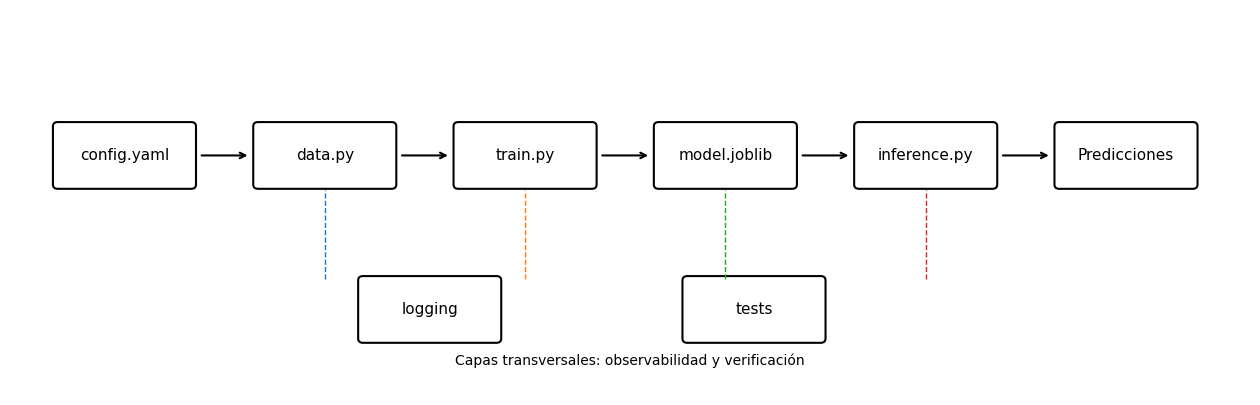

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

nodes = [
    ("config.yaml", 1.2, 2.8),
    ("data.py", 3.3, 2.8),
    ("train.py", 5.4, 2.8),
    ("model.joblib", 7.5, 2.8),
    ("inference.py", 9.6, 2.8),
    ("Predicciones", 11.7, 2.8),
    ("logging", 4.4, 1.0),
    ("tests", 7.8, 1.0),
]

fig, ax = plt.subplots(figsize=(16, 5))
ax.set_xlim(0, 13)
ax.set_ylim(0, 4.5)
ax.axis("off")

for label, x, y in nodes:
    box = FancyBboxPatch(
        (x - 0.72, y - 0.36), 1.44, 0.72,
        boxstyle="round,pad=0.03,rounding_size=0.05",
        fill=False, linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(x, y, label, ha="center", va="center", fontsize=11)

top_x = [1.2, 3.3, 5.4, 7.5, 9.6, 11.7]
for left, right in zip(top_x[:-1], top_x[1:]):
    ax.annotate(
        "", xy=(right - 0.78, 2.8), xytext=(left + 0.78, 2.8),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

for x in [3.3, 5.4, 7.5, 9.6]:
    ax.plot([x, x], [1.36, 2.4], linestyle="--", linewidth=1)

ax.text(
    6.5, 0.35,
    "Capas transversales: observabilidad y verificación",
    ha="center", fontsize=10
)
plt.show()

## 18. Empaquetar el proyecto generado

El siguiente bloque crea un `.zip` de la arquitectura completa dentro de Colab.

In [ ]:
import shutil
from pathlib import Path

zip_file = shutil.make_archive(
    base_name=str(PROJECT_ROOT.parent / "mlops_professional_project"),
    format="zip",
    root_dir=PROJECT_ROOT
)

print("ZIP creado:", zip_file)

ZIP creado: /content/mlops_professional_project.zip


## 19. Ejercicios propuestos

1. Añade un segundo modelo y selecciónalo usando validación.
2. Crea `config_dev.yaml` y `config_prod.yaml`.
3. Agrega una prueba que rechace columnas extra.
4. Registra tiempo de entrenamiento y tamaño del modelo.
5. Añade una carpeta `notebooks/` solo para exploración.
6. Diseña una política de versionado para modelo y dataset.
7. Explica qué archivos subirías a Git y cuáles excluirías con `.gitignore`.
8. Convierte `predict()` en un endpoint FastAPI en una sesión posterior.

### Preguntas de comprobación
- ¿Qué problema resuelve separar configuración de código?
- ¿Por qué `train.py` e `inference.py` deben estar separados?
- ¿Qué diferencia existe entre logging y `print()`?
- ¿Por qué es útil fallar si no se cumple un quality gate?
- ¿Qué partes de esta arquitectura podrían automatizarse con CI/CD?

## Errores de arquitectura que debes reconocer
- **Rutas absolutas repartidas en scripts:** hacen el proyecto frágil al moverlo.
- **Una función que descarga, limpia, entrena y predice:** mezcla responsabilidades y dificulta pruebas.
- **Credenciales dentro de YAML versionado:** convierte configuración en una fuga de secretos.
- **Artefactos sin schema:** inferencia no puede verificar compatibilidad de entradas.
- **Logs sin niveles ni timestamps:** pierden valor operativo.
- **Pruebas que solo ejecutan funciones:** no verifican invariantes ni resultados.
- **Promoción sin quality gate:** un pipeline automatizado puede desplegar una regresión de desempeño.

## Laboratorio adicional A — `.gitignore`: qué NO debe versionarse

Un repositorio profesional normalmente excluye:
- cachés;
- entornos virtuales;
- logs;
- modelos generados;
- archivos `.env`;
- temporales de notebooks.

La intención es mantener Git centrado en **código, configuración segura y documentación**, no en residuos de ejecución.

In [ ]:
gitignore = "\n".join([
    "# Python cache",
    "__pycache__/",
    "*.py[cod]",
    "",
    "# Entornos virtuales",
    ".venv/",
    "venv/",
    "",
    "# Logs generados",
    "logs/*.log",
    "",
    "# Modelos generados",
    "models/*.joblib",
    "",
    "# Variables de entorno potencialmente sensibles",
    ".env",
    "",
    "# Temporales de notebooks",
    ".ipynb_checkpoints/",
]) + "\n"

gitignore_path = (
    PROJECT_ROOT
    / ".gitignore"
)

gitignore_path.write_text(
    gitignore,
    encoding="utf-8"
)

print(
    gitignore_path.read_text()
)

# Python cache
__pycache__/
*.py[cod]

# Entornos virtuales
.venv/
venv/

# Logs generados
logs/*.log

# Modelos generados
models/*.joblib

# Variables de entorno potencialmente sensibles
.env

# Temporales de notebooks
.ipynb_checkpoints/



## Laboratorio adicional B — Configuración por entorno

**DEV**, **TEST/STAGING** y **PROD** pueden ejecutar el mismo código con parámetros distintos.

Ejemplo:
- DEV: logs detallados y umbrales relajados para experimentar.
- TEST: configuración próxima a producción.
- PROD: políticas estrictas y observabilidad estable.

La idea es evitar copiar y modificar el código para cada entorno.

In [ ]:
dev_config = "\n".join([
    "environment: development",
    "logging_level: DEBUG",
    "minimum_roc_auc: 0.85",
]) + "\n"

prod_config = "\n".join([
    "environment: production",
    "logging_level: INFO",
    "minimum_roc_auc: 0.90",
]) + "\n"

(
    PROJECT_ROOT
    / "config/config_dev.yaml"
).write_text(
    dev_config,
    encoding="utf-8"
)

(
    PROJECT_ROOT
    / "config/config_prod.yaml"
).write_text(
    prod_config,
    encoding="utf-8"
)

print("DEV:")
print(dev_config)

print("PROD:")
print(prod_config)

DEV:
environment: development
logging_level: DEBUG
minimum_roc_auc: 0.85

PROD:
environment: production
logging_level: INFO
minimum_roc_auc: 0.90



## Laboratorio adicional C — Data contract

Un **data contract** formaliza lo que un componente espera recibir y producir.

Puede incluir:
- columnas requeridas;
- tipos;
- nulabilidad;
- rangos;
- categorías;
- semántica;
- versión del contrato.

Aquí construiremos una versión mínima a partir del `schema.json`.

In [ ]:
schema_path = resolve_project_path(
    PROJECT_ROOT,
    config["model"]["schema_path"]
)

schema = json.loads(
    schema_path.read_text(
        encoding="utf-8"
    )
)

data_contract = {
    "contract_version": "1.0.0",
    "input": {
        "required_columns": schema[
            "feature_names"
        ],
        "number_of_features": schema[
            "n_features"
        ],
        "missing_values_allowed": False,
        "expected_type": "numeric"
    },
    "output": {
        "prediction": "integer class",
        "probability_class_1": "float in [0, 1]"
    }
}

contract_path = (
    PROJECT_ROOT
    / "models/data_contract.json"
)

contract_path.write_text(
    json.dumps(
        data_contract,
        indent=2
    ),
    encoding="utf-8"
)

print(
    contract_path.read_text()
)

{
  "contract_version": "1.0.0",
  "input": {
    "required_columns": [
      "mean radius",
      "mean texture",
      "mean perimeter",
      "mean area",
      "mean smoothness",
      "mean compactness",
      "mean concavity",
      "mean concave points",
      "mean symmetry",
      "mean fractal dimension",
      "radius error",
      "texture error",
      "perimeter error",
      "area error",
      "smoothness error",
      "compactness error",
      "concavity error",
      "concave points error",
      "symmetry error",
      "fractal dimension error",
      "worst radius",
      "worst texture",
      "worst perimeter",
      "worst area",
      "worst smoothness",
      "worst compactness",
      "worst concavity",
      "worst concave points",
      "worst symmetry",
      "worst fractal dimension"
    ],
    "number_of_features": 30,
    "missing_values_allowed": false,
    "expected_type": "numeric"
  },
  "output": {
    "prediction": "integer class",
    "probabilit

## Laboratorio adicional D — `pipeline.py`: ejecutar sin notebook

Un proyecto MLOps debe poder ejecutarse de forma no interactiva.

Crearemos un **entry point** para que el flujo completo pueda lanzarse con:

```bash
python pipeline.py
```

Esto prepara el proyecto para CI/CD, Docker y orquestadores.

In [ ]:
pipeline_py = """
from pathlib import Path
import sys

PROJECT_ROOT = Path(__file__).resolve().parent
sys.path.insert(
    0,
    str(PROJECT_ROOT / "src")
)

from mlops_demo.config import (
    load_config,
    resolve_project_path,
)
from mlops_demo.logging_utils import build_logger
from mlops_demo.data import (
    create_raw_dataset,
    split_and_save,
)
from mlops_demo.train import train_model

def main():
    # Fuente única de parámetros.
    config = load_config(
        PROJECT_ROOT / "config/config.yaml"
    )

    # Configuramos logging antes del resto para capturar todo el flujo.
    log_file = resolve_project_path(
        PROJECT_ROOT,
        config["logging"]["file_path"]
    )

    logger = build_logger(
        "mlops_demo_cli",
        log_file,
        config["logging"]["level"]
    )

    # Capa raw reproducible.
    raw_path = create_raw_dataset(
        PROJECT_ROOT,
        config
    )

    logger.info(
        "Raw dataset: %s",
        raw_path
    )

    # Validación y particionado.
    split_and_save(
        PROJECT_ROOT,
        config
    )

    # Entrenamiento, quality gate y artefactos.
    metrics = train_model(
        PROJECT_ROOT,
        config,
        logger=logger
    )

    logger.info(
        "Pipeline finalizado correctamente: %s",
        metrics
    )

if __name__ == "__main__":
    main()
"""

pipeline_path = (
    PROJECT_ROOT
    / "pipeline.py"
)

pipeline_path.write_text(
    textwrap.dedent(
        pipeline_py
    ).strip() + "\n",
    encoding="utf-8"
)

print(
    pipeline_path.read_text()
)

from pathlib import Path
import sys

PROJECT_ROOT = Path(__file__).resolve().parent
sys.path.insert(
    0,
    str(PROJECT_ROOT / "src")
)

from mlops_demo.config import (
    load_config,
    resolve_project_path,
)
from mlops_demo.logging_utils import build_logger
from mlops_demo.data import (
    create_raw_dataset,
    split_and_save,
)
from mlops_demo.train import train_model

def main():
    # Fuente única de parámetros.
    config = load_config(
        PROJECT_ROOT / "config/config.yaml"
    )

    # Configuramos logging antes del resto para capturar todo el flujo.
    log_file = resolve_project_path(
        PROJECT_ROOT,
        config["logging"]["file_path"]
    )

    logger = build_logger(
        "mlops_demo_cli",
        log_file,
        config["logging"]["level"]
    )

    # Capa raw reproducible.
    raw_path = create_raw_dataset(
        PROJECT_ROOT,
        config
    )

    logger.info(
        "Raw dataset: %s",
        raw_path
    )

    # Validación y partic

In [ ]:
# Ejecutamos el entry point como proceso independiente.
# Si funciona, demostramos que el pipeline no depende del estado del notebook.
cli_run = subprocess.run(
    [
        sys.executable,
        "pipeline.py"
    ],
    cwd=PROJECT_ROOT,
    text=True,
    capture_output=True
)

print(
    "Return code:",
    cli_run.returncode
)

print("\nSTDOUT:")
print(
    cli_run.stdout
)

print("\nSTDERR / logging:")
print(
    cli_run.stderr
)

if cli_run.returncode != 0:
    raise RuntimeError(
        "pipeline.py no terminó correctamente."
    )

Return code: 0

STDOUT:


STDERR / logging:
2026-10-06 00:32:35,084 | INFO | mlops_demo_cli | Raw dataset: /content/mlops_professional_project/data/raw/breast_cancer.csv
2026-10-06 00:32:35,131 | INFO | mlops_demo_cli | Entrenamiento iniciado | train=397 valid=86 test=86
2026-10-06 00:32:35,177 | INFO | mlops_demo_cli | Entrenamiento completado | valid_roc_auc=1.0000 | test_roc_auc=0.9948
2026-10-06 00:32:35,177 | INFO | mlops_demo_cli | Pipeline finalizado correctamente: {'validation': {'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'roc_auc': 1.0}, 'test': {'accuracy': 0.9651162790697675, 'precision': 0.9811320754716981, 'recall': 0.9629629629629629, 'f1': 0.9719626168224299, 'roc_auc': 0.9947916666666666}}



## Laboratorio adicional E — Smoke test

Un **smoke test** responde rápidamente:

> ¿Puedo cargar el artefacto y obtener una predicción válida ahora mismo?

No sustituye los tests exhaustivos; sirve como verificación rápida después de un despliegue.

In [ ]:
from mlops_demo.inference import predict

# Usamos una sola fila válida para que el test sea rápido.
smoke_input = (
    sample_features
    .head(1)
)

smoke_output = predict(
    PROJECT_ROOT,
    config,
    smoke_input
)

# Verificamos invariantes mínimas de la API de inferencia.
assert len(
    smoke_output
) == 1

assert "prediction" in (
    smoke_output.columns
)

assert "probability_class_1" in (
    smoke_output.columns
)

assert smoke_output[
    "probability_class_1"
].between(
    0,
    1
).all()

print(
    "Smoke test: PASS"
)

display(
    smoke_output
)

Smoke test: PASS


,prediction,probability_class_1
0,0,0.211895


## Laboratorio adicional F — Prueba negativa del esquema

Un buen sistema no solo “funciona cuando todo está bien”. También debe rechazar entradas inválidas de manera controlada.

In [ ]:
# Quitamos una feature obligatoria.
invalid_smoke_input = (
    smoke_input
    .drop(
        columns=[
            smoke_input.columns[0]
        ]
    )
)

try:
    predict(
        PROJECT_ROOT,
        config,
        invalid_smoke_input
    )

    # Si no se produjo ValueError, la validación del contrato no funcionó.
    raise AssertionError(
        "El sistema aceptó una entrada inválida."
    )

except ValueError as exc:
    print(
        "Prueba negativa: PASS ->",
        exc
    )

Prueba negativa: PASS -> Faltan columnas: ['mean radius']


## Laboratorio adicional G — Manifiesto del modelo

Un despliegue debería poder responder:
- qué archivo se desplegó;
- qué hash tiene;
- qué esquema utiliza;
- qué métricas obtuvo;
- cuándo fue generado.

El manifiesto reúne esa trazabilidad.

In [ ]:
import hashlib
from datetime import datetime, timezone

def file_sha256(path: Path) -> str:
    # SHA-256 identifica el contenido exacto del archivo.
    digest = hashlib.sha256()

    with path.open(
        "rb"
    ) as file_handle:
        for block in iter(
            lambda: file_handle.read(
                1024 * 1024
            ),
            b""
        ):
            digest.update(
                block
            )

    return digest.hexdigest()

model_path = resolve_project_path(
    PROJECT_ROOT,
    config["model"]["model_path"]
)

metrics_path = resolve_project_path(
    PROJECT_ROOT,
    config["reports"]["metrics_path"]
)

manifest = {
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "model_path": str(
        model_path.relative_to(
            PROJECT_ROOT
        )
    ),
    "model_sha256": file_sha256(
        model_path
    ),
    "schema_path": str(
        schema_path.relative_to(
            PROJECT_ROOT
        )
    ),
    "schema_sha256": file_sha256(
        schema_path
    ),
    "metrics_path": str(
        metrics_path.relative_to(
            PROJECT_ROOT
        )
    ),
    "metrics": json.loads(
        metrics_path.read_text(
            encoding="utf-8"
        )
    )
}

manifest_path = (
    PROJECT_ROOT
    / "models/model_manifest.json"
)

manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2
    ),
    encoding="utf-8"
)

print(
    manifest_path.read_text()
)

{
  "created_at_utc": "2026-10-06T00:32:35.522442+00:00",
  "model_path": "models/model.joblib",
  "model_sha256": "35f589578a366f8bdff6d726b64efc920fe2dd2c412e2d88ec2ba557bb67a871",
  "schema_path": "models/schema.json",
  "schema_sha256": "24205034f807144a2faaebcf101e6a46917216144f889ed046e0a466cfcccc7b",
  "metrics_path": "reports/metrics.json",
  "metrics": {
    "validation": {
      "accuracy": 1.0,
      "precision": 1.0,
      "recall": 1.0,
      "f1": 1.0,
      "roc_auc": 1.0
    },
    "test": {
      "accuracy": 0.9651162790697675,
      "precision": 0.9811320754716981,
      "recall": 0.9629629629629629,
      "f1": 0.9719626168224299,
      "roc_auc": 0.9947916666666666
    }
  }
}


## Laboratorio adicional H — Árbol final del proyecto

Ahora el proyecto contiene:
- configuración;
- datos raw y procesados;
- código modular;
- entry point;
- modelo;
- contrato;
- métricas;
- logs;
- tests;
- manifiesto;
- reglas para Git.

In [ ]:
def print_tree(
    root: Path,
    max_depth: int = 4
):
    # Limitamos profundidad para mantener la salida legible.
    root = root.resolve()

    for path in sorted(
        root.rglob("*")
    ):
        relative = path.relative_to(
            root
        )

        if len(
            relative.parts
        ) > max_depth:
            continue

        indent = (
            "    "
            * (
                len(relative.parts)
                - 1
            )
        )

        marker = (
            "[DIR]"
            if path.is_dir()
            else "[FILE]"
        )

        print(
            f"{indent}{marker} {relative.name}"
        )

print_tree(
    PROJECT_ROOT
)

[FILE] .gitignore
[DIR] .pytest_cache
    [FILE] .gitignore
    [FILE] CACHEDIR.TAG
    [FILE] README.md
    [DIR] v
        [DIR] cache
            [FILE] nodeids
[FILE] README.md
[DIR] config
    [FILE] config.yaml
    [FILE] config_dev.yaml
    [FILE] config_prod.yaml
[DIR] data
    [DIR] processed
        [FILE] test.csv
        [FILE] train.csv
        [FILE] valid.csv
    [DIR] raw
        [FILE] breast_cancer.csv
[DIR] logs
    [FILE] pipeline.log
[DIR] models
    [FILE] data_contract.json
    [FILE] model.joblib
    [FILE] model_manifest.json
    [FILE] schema.json
[FILE] pipeline.py
[DIR] reports
    [FILE] metrics.json
[FILE] requirements.txt
[DIR] src
    [DIR] mlops_demo
        [FILE] __init__.py
        [DIR] __pycache__
            [FILE] __init__.cpython-313.pyc
            [FILE] config.cpython-313.pyc
            [FILE] data.cpython-313.pyc
            [FILE] inference.cpython-313.pyc
            [FILE] logging_utils.cpython-313.pyc
            [FILE] train.cpython-31

## Vista previa de CI/CD

En **Continuous Integration (CI)** podríamos automatizar:

1. instalar dependencias;
2. ejecutar tests;
3. validar esquemas;
4. entrenar un candidato;
5. verificar quality gates;
6. publicar artefactos.

En **Continuous Delivery/Deployment (CD)** añadiríamos:
- empaquetado;
- imagen Docker;
- staging;
- smoke tests;
- despliegue;
- rollback.

La herramienta —por ejemplo GitHub Actions— viene después. Primero necesitamos un proyecto ejecutable y verificable.

## Mini evaluación de la Sesión 2

1. ¿Por qué una ruta absoluta dentro de `train.py` es mala práctica?
2. ¿Qué diferencia existe entre `schema` y `data contract`?
3. ¿Por qué `pipeline.py` mejora la automatización?
4. ¿Qué diferencia existe entre un unit test y un smoke test?
5. ¿Por qué un secreto no debe estar en `config.yaml`?
6. ¿Qué información aporta un hash SHA-256?

<details>
<summary><b>Ver respuestas</b></summary>

1. Porque hace que el módulo dependa del equipo donde fue escrito.
2. El schema describe estructura; el contrato añade reglas y expectativas operativas/semánticas.
3. Porque permite ejecutar todo el flujo sin depender de Jupyter.
4. Unit test verifica una unidad pequeña; smoke test comprueba rápidamente que el sistema crítico está operativo.
5. Porque la configuración suele versionarse o compartirse.
6. Una huella de integridad que identifica el contenido exacto del archivo.

</details>

## 20. Resumen

La profesionalización de un proyecto ML empieza por una base ordenada:

**estructura + configuración + separación de responsabilidades + validación + logs + pruebas + artefactos reproducibles.**

Las herramientas avanzadas se integran mejor cuando esta base ya existe.